In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


file_path = r"C:\Users\LOQ\Gwalior AQI Project\01_Data_Collection\gwalior_air_quality_historical.csv"

df = pd.read_csv(file_path)


data = df.copy()

data["timestamp"] = pd.to_datetime(
    data["timestamp"], errors="coerce"
)

print("Dataset shape:", data.shape)
display(data.head())
display(data.tail())
data.info()

Dataset shape: (45227, 9)


,timestamp,pm25,pm10,no2,co,so2,o3,temperature,humidity
0,2025-02-19 01:30:00+05:30,127.0,171.0,24.5,1.60,17.3,22.0,14.2,94.0
1,2025-02-19 01:45:00+05:30,127.0,171.0,24.0,1.85,16.6,20.3,14.2,94.0
2,2025-02-19 02:00:00+05:30,127.0,NaN,23.2,1.72,17.6,20.6,14.3,95.0
3,2025-02-19 02:15:00+05:30,127.0,171.0,20.6,1.73,18.1,21.5,14.2,95.0
4,2025-02-19 02:30:00+05:30,108.0,135.0,18.0,1.74,18.1,20.9,14.1,95.0


,timestamp,pm25,pm10,no2,co,so2,o3,temperature,humidity
45222,2026-09-17 18:45:00+05:30,17.0,26.0,51.6,0.92,14.6,53.9,25.2,94.0
45223,2026-09-17 19:00:00+05:30,17.0,26.0,53.0,0.80,15.8,50.8,24.9,94.0
45224,2026-09-17 19:15:00+05:30,17.0,26.0,52.8,0.81,15.7,48.2,24.7,94.0
45225,2026-09-17 19:30:00+05:30,16.0,23.0,53.4,0.81,16.0,47.8,24.5,95.0
45226,2026-09-17 19:45:00+05:30,16.0,23.0,54.6,0.85,15.4,51.5,24.5,95.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45227 entries, 0 to 45226
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype                    
---  ------       --------------  -----                    
 0   timestamp    45227 non-null  datetime64[ns, UTC+05:30]
 1   pm25         44405 non-null  float64                  
 2   pm10         42075 non-null  float64                  
 3   no2          43052 non-null  float64                  
 4   co           41874 non-null  float64                  
 5   so2          41086 non-null  float64                  
 6   o3           42521 non-null  float64                  
 7   temperature  45184 non-null  float64                  
 8   humidity     45173 non-null  float64                  
dtypes: datetime64[ns, UTC+05:30](1), float64(8)
memory usage: 3.1 MB


In [2]:
print("Rows and columns:", data.shape)

print("\nMissing values:")
missing = pd.DataFrame({
    "Missing_Count": data.isna().sum(),
    "Missing_Percent": (data.isna().mean() * 100).round(2)
})
display(missing)

print("\nDuplicate complete rows:", data.duplicated().sum())
print("Duplicate timestamps:", data["timestamp"].duplicated().sum())

print("\nDate range:")
print("Start:", data["timestamp"].min())
print("End:", data["timestamp"].max())

print("\nNumeric summary:")
display(data.describe().T.round(2))

Rows and columns: (45227, 9)

Missing values:


,Missing_Count,Missing_Percent
timestamp,0,0.00
pm25,822,1.82
pm10,3152,6.97
no2,2175,4.81
co,3353,7.41
so2,4141,9.16
o3,2706,5.98
temperature,43,0.10
humidity,54,0.12



Duplicate complete rows: 0
Duplicate timestamps: 0

Date range:
Start: 2025-02-19 01:30:00+05:30
End: 2026-09-17 19:45:00+05:30

Numeric summary:


,count,mean,std,min,25%,50%,75%,max
pm25,44405.0,38.59,34.36,1.0,17.00,27.00,48.00,585.00
pm10,42075.0,84.00,63.67,1.0,39.00,66.00,112.00,970.00
no2,43052.0,24.05,23.58,0.0,6.60,15.30,34.20,211.60
co,41874.0,0.90,0.77,0.0,0.48,0.69,0.98,9.65
so2,41086.0,15.80,19.28,0.0,10.00,14.10,19.80,1441.70
o3,42521.0,51.12,31.02,0.0,29.20,43.50,64.20,480.40
temperature,45184.0,27.75,7.97,5.6,23.10,28.60,32.90,48.10
humidity,45173.0,69.12,23.54,8.0,51.00,74.00,91.00,97.00


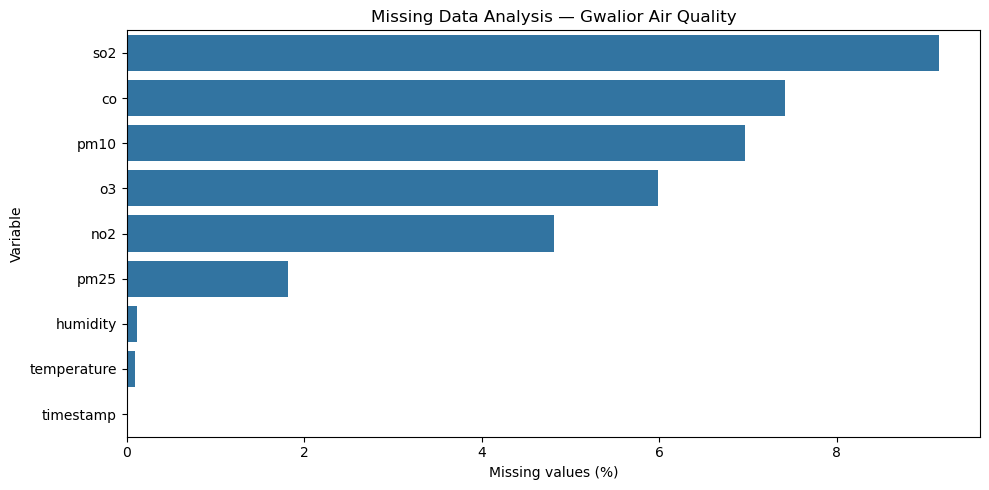

In [3]:
missing_percent = (
    data.isna().mean().mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)
plt.xlabel("Missing values (%)")
plt.ylabel("Variable")
plt.title("Missing Data Analysis — Gwalior Air Quality")
plt.tight_layout()
plt.show()

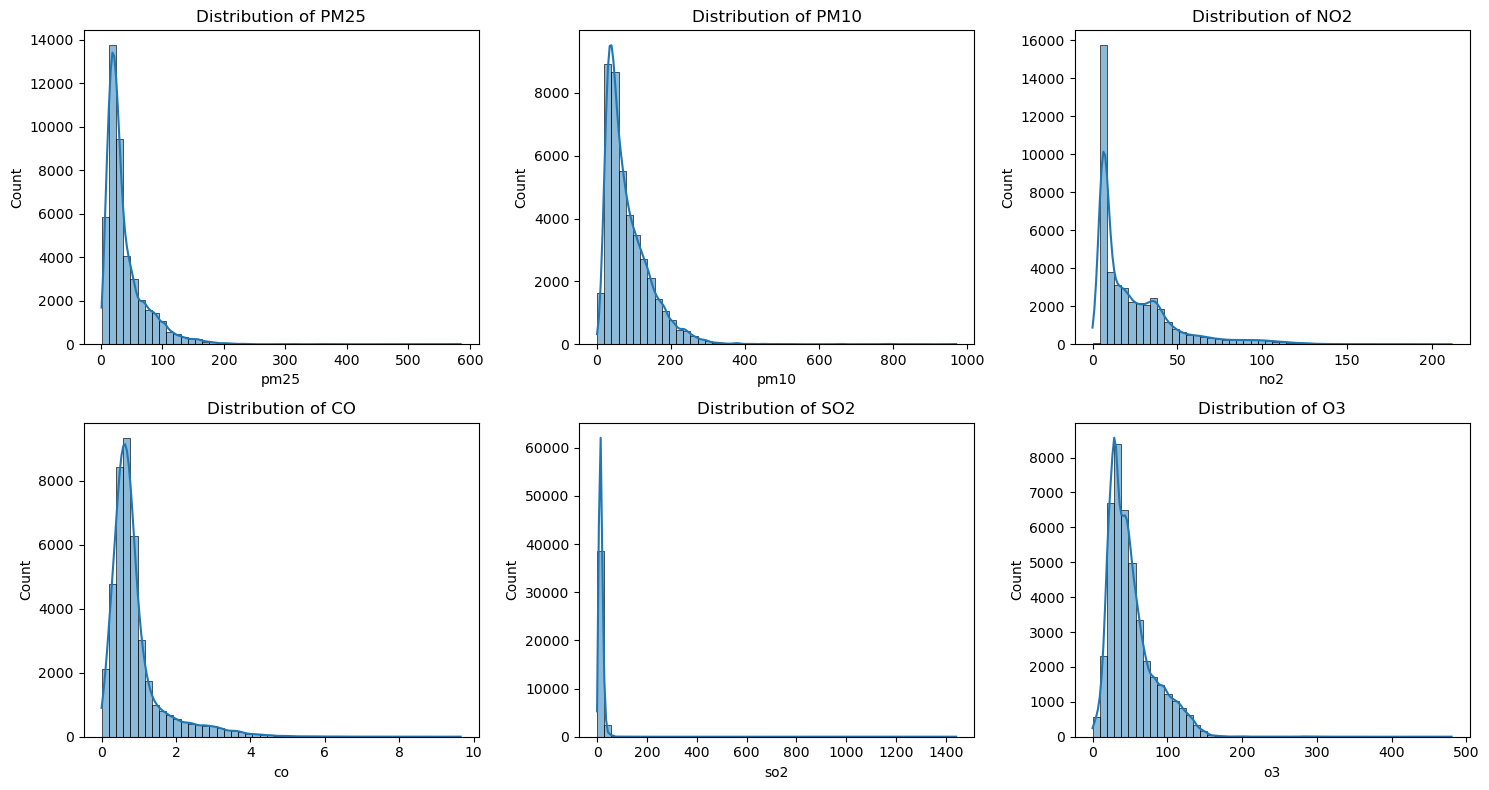

In [4]:
pollutants = ["pm25", "pm10", "no2", "co", "so2", "o3"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, ax in zip(pollutants, axes.flatten()):
    sns.histplot(
        data=data,
        x=col,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {col.upper()}")

plt.tight_layout()
plt.show()

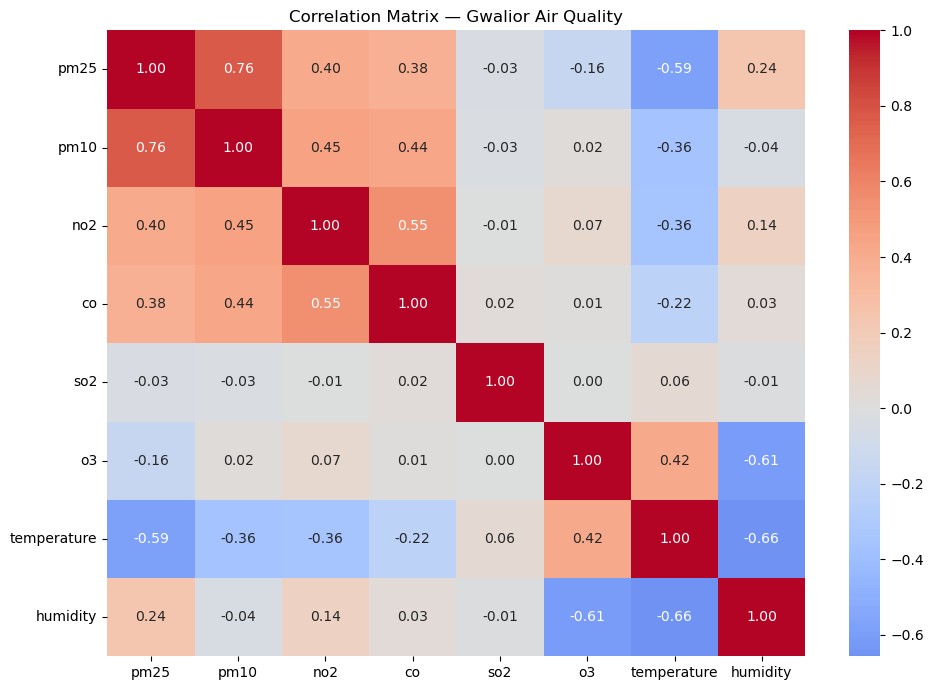

In [5]:
numeric_cols = [
    "pm25", "pm10", "no2", "co",
    "so2", "o3", "temperature", "humidity"
]

correlation = data[numeric_cols].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix — Gwalior Air Quality")
plt.tight_layout()
plt.show()

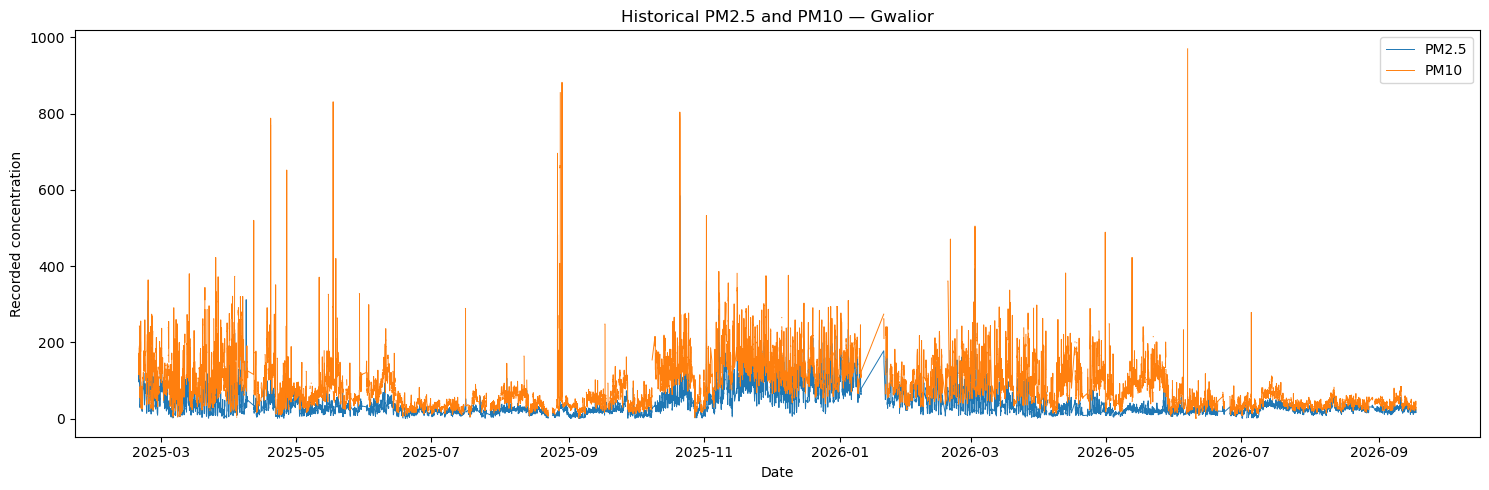

In [6]:
data = data.sort_values("timestamp")

plt.figure(figsize=(15, 5))
plt.plot(
    data["timestamp"],
    data["pm25"],
    linewidth=0.7,
    label="PM2.5"
)
plt.plot(
    data["timestamp"],
    data["pm10"],
    linewidth=0.7,
    label="PM10"
)

plt.xlabel("Date")
plt.ylabel("Recorded concentration")
plt.title("Historical PM2.5 and PM10 — Gwalior")
plt.legend()
plt.tight_layout()
plt.show()


In [7]:
pollutants = ["pm25", "pm10", "no2", "co", "so2", "o3"]

for col in pollutants:
    print(f"\n--- Top 10 values: {col.upper()} ---")
    print(
        data[["timestamp", col]]
        .dropna()
        .nlargest(10, col)
        .to_string(index=False)
    )


--- Top 10 values: PM25 ---
                timestamp  pm25
2025-10-20 22:30:00+05:30 585.0
2025-10-20 22:45:00+05:30 585.0
2025-10-20 23:00:00+05:30 585.0
2025-10-20 23:15:00+05:30 585.0
2025-10-21 00:30:00+05:30 547.0
2025-10-21 00:45:00+05:30 547.0
2025-10-21 01:00:00+05:30 547.0
2025-10-21 01:15:00+05:30 547.0
2026-03-02 23:30:00+05:30 394.0
2026-03-02 23:45:00+05:30 394.0

--- Top 10 values: PM10 ---
                timestamp  pm10
2026-06-06 19:30:00+05:30 970.0
2026-06-06 19:45:00+05:30 970.0
2026-06-06 20:00:00+05:30 970.0
2026-06-06 20:15:00+05:30 970.0
2025-08-28 20:30:00+05:30 882.0
2025-08-28 20:45:00+05:30 882.0
2025-08-28 21:00:00+05:30 882.0
2025-08-28 01:30:00+05:30 855.0
2025-08-28 01:45:00+05:30 855.0
2025-08-28 02:00:00+05:30 855.0

--- Top 10 values: NO2 ---
                timestamp   no2
2025-12-22 14:30:00+05:30 211.6
2025-12-23 19:00:00+05:30 181.8
2026-01-03 11:45:00+05:30 180.5
2026-01-28 13:30:00+05:30 180.3
2025-12-22 14:45:00+05:30 165.0
2025-12-05 18:30:0

In [8]:
# Ensure timestamps are in datetime format
data["timestamp"] = pd.to_datetime(data["timestamp"], errors="coerce")

# Events to investigate
events = {
    "PM2.5 extreme": "2025-10-20 22:30:00+05:30",
    "PM10 extreme": "2026-06-06 19:30:00+05:30",
    "SO2 extreme": "2026-06-16 06:15:00+05:30",
    "O3 extreme": "2025-05-28 01:15:00+05:30"
}

cols = [
    "timestamp", "pm25", "pm10", "no2", "co",
    "so2", "o3", "temperature", "humidity"
]

for event_name, event_time in events.items():
    event_time = pd.Timestamp(event_time)

    mask = (
        (data["timestamp"] >= event_time - pd.Timedelta(hours=2))
        & (data["timestamp"] <= event_time + pd.Timedelta(hours=2))
    )

    print(f"\n{'=' * 20} {event_name} {'=' * 20}")
    print(
        data.loc[mask, cols]
        .sort_values("timestamp")
        .to_string(index=False)
    )


==================== PM2.5 extreme ====================
                timestamp  pm25  pm10  no2   co  so2   o3  temperature  humidity
2025-10-20 22:15:00+05:30 301.0 440.0 50.9 1.39 19.3 61.1         21.5      93.0
2025-10-20 22:30:00+05:30 585.0 804.0 58.2 1.45 20.7 66.9         21.4      93.0
2025-10-20 22:45:00+05:30 585.0 804.0 63.2 1.50 23.1 46.5         21.3      94.0
2025-10-20 23:00:00+05:30 585.0 804.0 64.1 1.33 19.5 48.0         21.3      94.0
2025-10-20 23:15:00+05:30 585.0 804.0 62.4 1.29 16.0 42.6         21.2      94.0
2025-10-21 00:30:00+05:30 547.0 786.0 46.9 0.88  2.5  NaN         20.6      95.0

==================== PM10 extreme ====================
                timestamp  pm25  pm10  no2   co  so2    o3  temperature  humidity
2026-06-06 17:30:00+05:30  19.0  35.0 13.5 0.17 16.7 110.9         40.2      36.0
2026-06-06 17:45:00+05:30  19.0  35.0 15.3 0.26 16.2 107.1         39.6      36.0
2026-06-06 18:00:00+05:30  19.0  35.0 15.3 0.30 15.3 101.4         39.0   

In [9]:
print(data["timestamp"].dtype)
print(data["timestamp"].head())

datetime64[ns, UTC+05:30]
0   2025-02-19 01:30:00+05:30
1   2025-02-19 01:45:00+05:30
2   2025-02-19 02:00:00+05:30
3   2025-02-19 02:15:00+05:30
4   2025-02-19 02:30:00+05:30
Name: timestamp, dtype: datetime64[ns, UTC+05:30]


In [10]:
clean_data = data.copy()

clean_data = clean_data.sort_values("timestamp").reset_index(drop=True)

print(clean_data["timestamp"].is_monotonic_increasing)


True


In [11]:
missing = clean_data.isnull().sum()

print(missing[missing > 0])


pm25            822
pm10           3152
no2            2175
co             3353
so2            4141
o3             2706
temperature      43
humidity         54
dtype: int64


In [12]:
missing_rows = clean_data.isnull().any(axis=1).sum()

print("Rows containing at least one missing value:", missing_rows)

Rows containing at least one missing value: 13119


In [13]:
cols = [
    "pm25", "pm10", "no2", "co",
    "so2", "o3", "temperature", "humidity"
]

clean_data = clean_data.set_index("timestamp")

clean_data[cols] = clean_data[cols].interpolate(
    method="time",
    limit=4,
    limit_area="inside"
)

clean_data = clean_data.reset_index()

print(clean_data[cols].isnull().sum())

pm25            473
pm10            466
no2             295
co              601
so2            1083
o3              702
temperature       0
humidity          6
dtype: int64


In [14]:
remaining = clean_data[cols].isnull().mean() * 100

print(remaining.round(2))

pm25           1.05
pm10           1.03
no2            0.65
co             1.33
so2            2.39
o3             1.55
temperature    0.00
humidity       0.01
dtype: float64


In [15]:
pollutants = ["pm25", "pm10", "no2", "co", "so2", "o3"]

all_pollutants_missing = clean_data[pollutants].isnull().all(axis=1).sum()

print("Rows with all pollutant readings missing:", all_pollutants_missing)


Rows with all pollutant readings missing: 0


In [16]:
print("Total missing values:", clean_data.isnull().sum().sum())
print("Total rows:", len(clean_data))

Total missing values: 3626
Total rows: 45227


In [ ]:
# now feature 


In [17]:
clean_data["hour"] = clean_data["timestamp"].dt.hour
clean_data["day"] = clean_data["timestamp"].dt.day
clean_data["month"] = clean_data["timestamp"].dt.month
clean_data["day_of_week"] = clean_data["timestamp"].dt.dayofweek

print(clean_data[["timestamp", "hour", "day", "month", "day_of_week"]].head())

                  timestamp  hour  day  month  day_of_week
0 2025-02-19 01:30:00+05:30     1   19      2            2
1 2025-02-19 01:45:00+05:30     1   19      2            2
2 2025-02-19 02:00:00+05:30     2   19      2            2
3 2025-02-19 02:15:00+05:30     2   19      2            2
4 2025-02-19 02:30:00+05:30     2   19      2            2


In [18]:
clean_data["is_weekend"] = (
    clean_data["day_of_week"] >= 5
).astype(int)

print(clean_data[["timestamp", "day_of_week", "is_weekend"]].head())

                  timestamp  day_of_week  is_weekend
0 2025-02-19 01:30:00+05:30            2           0
1 2025-02-19 01:45:00+05:30            2           0
2 2025-02-19 02:00:00+05:30            2           0
3 2025-02-19 02:15:00+05:30            2           0
4 2025-02-19 02:30:00+05:30            2           0


In [19]:
clean_data["pm25_previous"] = clean_data["pm25"].shift(1)

print(clean_data[["timestamp", "pm25", "pm25_previous"]].head(10))

                  timestamp   pm25  pm25_previous
0 2025-02-19 01:30:00+05:30  127.0            NaN
1 2025-02-19 01:45:00+05:30  127.0          127.0
2 2025-02-19 02:00:00+05:30  127.0          127.0
3 2025-02-19 02:15:00+05:30  127.0          127.0
4 2025-02-19 02:30:00+05:30  108.0          127.0
5 2025-02-19 02:45:00+05:30  108.0          108.0
6 2025-02-19 03:00:00+05:30  108.0          108.0
7 2025-02-19 03:15:00+05:30  108.0          108.0
8 2025-02-19 03:30:00+05:30   96.0          108.0
9 2025-02-19 03:45:00+05:30   96.0           96.0


In [20]:
time_gaps = clean_data["timestamp"].diff()

print(time_gaps.value_counts().head(10))


timestamp
0 days 00:15:00    43165
0 days 00:30:00     1067
0 days 01:00:00      532
0 days 00:45:00      166
0 days 02:00:00       65
0 days 01:15:00       62
0 days 02:15:00       20
0 days 01:30:00       17
0 days 01:45:00       17
0 days 02:45:00       11
Name: count, dtype: int64


In [21]:
expected = pd.date_range(
    start=clean_data["timestamp"].min(),
    end=clean_data["timestamp"].max(),
    freq="15min"
)

actual = pd.DatetimeIndex(clean_data["timestamp"])

print("Expected timestamps:", len(expected))
print("Actual timestamps:", len(actual))
print("Missing timestamps:", len(expected.difference(actual)))

Expected timestamps: 55274
Actual timestamps: 45227
Missing timestamps: 10047


In [22]:
regular_data = (
    clean_data
    .set_index("timestamp")
    .asfreq("15min")
)

print("Rows after creating regular timeline:", len(regular_data))
print("Missing PM2.5 values:", regular_data["pm25"].isnull().sum())

Rows after creating regular timeline: 55274
Missing PM2.5 values: 10520


In [23]:
print(regular_data.isnull().sum())

pm25             10520
pm10             10513
no2              10342
co               10648
so2              11130
o3               10749
temperature      10047
humidity         10053
hour             10047
day              10047
month            10047
day_of_week      10047
is_weekend       10047
pm25_previous    10521
dtype: int64


In [24]:
regular_data[cols] = regular_data[cols].interpolate(
    method="time",
    limit=4,
    limit_area="inside"
)

print(regular_data[cols].isnull().sum())

pm25           6253
pm10           6288
no2            6035
co             6277
so2            6565
o3             6423
temperature    5868
humidity       5870
dtype: int64


In [25]:
missing_percent = regular_data[cols].isnull().mean() * 100

print(missing_percent.round(2))

pm25           11.31
pm10           11.38
no2            10.92
co             11.36
so2            11.88
o3             11.62
temperature    10.62
humidity       10.62
dtype: float64


In [26]:
missing_pm25 = regular_data["pm25"].isnull()

groups = missing_pm25.ne(missing_pm25.shift()).cumsum()

gap_lengths = (
    regular_data.loc[missing_pm25]
    .groupby(groups[missing_pm25])
    .size()
)

print("Longest missing PM2.5 gap (minutes):", gap_lengths.max() * 15)
print("Number of missing gaps:", len(gap_lengths))

Longest missing PM2.5 gap (minutes): 14505
Number of missing gaps: 249


In [27]:
gap_info = regular_data.loc[missing_pm25].groupby(groups[missing_pm25]).apply(
    lambda x: pd.Series({
        "start": x.index.min(),
        "end": x.index.max(),
        "missing_readings": len(x),
        "duration_hours": len(x) * 0.25
    })
)

print(gap_info.sort_values("duration_hours", ascending=False).head(5))

                         start                       end  missing_readings  \
pm25                                                                         
214  2026-01-10 18:45:00+05:30 2026-01-20 20:15:00+05:30               967   
10   2025-04-09 06:45:00+05:30 2025-04-11 19:30:00+05:30               244   
432  2026-06-23 17:30:00+05:30 2026-06-25 21:30:00+05:30               209   
426  2026-06-20 11:45:00+05:30 2026-06-22 14:15:00+05:30               203   
44   2025-05-30 16:45:00+05:30 2025-06-01 16:00:00+05:30               190   

      duration_hours  
pm25                  
214           241.75  
10             61.00  
432            52.25  
426            50.75  
44             47.50  


In [28]:
print("Available PM2.5 readings:", regular_data["pm25"].notna().sum())
print("Missing PM2.5 readings:", regular_data["pm25"].isna().sum())
print("Total timestamps:", len(regular_data))

Available PM2.5 readings: 49021
Missing PM2.5 readings: 6253
Total timestamps: 55274


In [29]:
forecast_data = regular_data.copy()

print("Dataset shape:", forecast_data.shape)
print("PM2.5 available:", forecast_data["pm25"].notna().sum())

Dataset shape: (55274, 14)
PM2.5 available: 49021


In [31]:
forecast_data = forecast_data.reset_index()

print(forecast_data.columns.tolist())

['timestamp', 'pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'pm25_previous', 'pm25_next_15min']


In [32]:
forecast_data["pm25_next_15min"] = forecast_data["pm25"].shift(-1)

print(
    forecast_data[
        ["timestamp", "pm25", "pm25_next_15min"]
    ].head(10)
)

                  timestamp   pm25  pm25_next_15min
0 2025-02-19 01:30:00+05:30  127.0            127.0
1 2025-02-19 01:45:00+05:30  127.0            127.0
2 2025-02-19 02:00:00+05:30  127.0            127.0
3 2025-02-19 02:15:00+05:30  127.0            108.0
4 2025-02-19 02:30:00+05:30  108.0            108.0
5 2025-02-19 02:45:00+05:30  108.0            108.0
6 2025-02-19 03:00:00+05:30  108.0            108.0
7 2025-02-19 03:15:00+05:30  108.0             96.0
8 2025-02-19 03:30:00+05:30   96.0             96.0
9 2025-02-19 03:45:00+05:30   96.0             96.0


In [33]:
forecast_data["pm25_next_1hour"] = forecast_data["pm25"].shift(-4)
forecast_data["pm25_next_24hours"] = forecast_data["pm25"].shift(-96)

print(
    forecast_data[
        ["timestamp", "pm25", "pm25_next_15min",
         "pm25_next_1hour", "pm25_next_24hours"]
    ].head(10)
)

                  timestamp   pm25  pm25_next_15min  pm25_next_1hour  \
0 2025-02-19 01:30:00+05:30  127.0            127.0            108.0   
1 2025-02-19 01:45:00+05:30  127.0            127.0            108.0   
2 2025-02-19 02:00:00+05:30  127.0            127.0            108.0   
3 2025-02-19 02:15:00+05:30  127.0            108.0            108.0   
4 2025-02-19 02:30:00+05:30  108.0            108.0             96.0   
5 2025-02-19 02:45:00+05:30  108.0            108.0             96.0   
6 2025-02-19 03:00:00+05:30  108.0            108.0             96.0   
7 2025-02-19 03:15:00+05:30  108.0             96.0             96.0   
8 2025-02-19 03:30:00+05:30   96.0             96.0            100.0   
9 2025-02-19 03:45:00+05:30   96.0             96.0            100.0   

   pm25_next_24hours  
0               38.0  
1               38.0  
2               38.0  
3               38.0  
4               37.0  
5               37.0  
6               37.0  
7               37.0  


In [34]:
print(forecast_data.columns.tolist())

['timestamp', 'pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'pm25_previous', 'pm25_next_15min', 'pm25_next_1hour', 'pm25_next_24hours']


In [35]:
pollutants = ["pm25", "pm10", "no2"]

horizons = {
    "15min": 1,
    "1hour": 4,
    "24hours": 96
}

for pollutant in pollutants:
    for horizon, steps in horizons.items():
        forecast_data[f"{pollutant}_next_{horizon}"] = (
            forecast_data[pollutant].shift(-steps)
        )

print("Prediction targets created:")
print([col for col in forecast_data.columns if "_next_" in col])

Prediction targets created:
['pm25_next_15min', 'pm25_next_1hour', 'pm25_next_24hours', 'pm10_next_15min', 'pm10_next_1hour', 'pm10_next_24hours', 'no2_next_15min', 'no2_next_1hour', 'no2_next_24hours']


In [36]:
target_columns = [
    "pm25_next_15min", "pm25_next_1hour", "pm25_next_24hours",
    "pm10_next_15min", "pm10_next_1hour", "pm10_next_24hours",
    "no2_next_15min", "no2_next_1hour", "no2_next_24hours"
]

print("Dataset shape:", forecast_data.shape)
print("\nMissing values in prediction targets:")
print(forecast_data[target_columns].isnull().sum())

print("\nRows with all 9 targets available:",
      forecast_data[target_columns].notna().all(axis=1).sum())

Dataset shape: (55274, 24)

Missing values in prediction targets:
pm25_next_15min      6254
pm25_next_1hour      6257
pm25_next_24hours    6349
pm10_next_15min      6289
pm10_next_1hour      6292
pm10_next_24hours    6384
no2_next_15min       6036
no2_next_1hour       6039
no2_next_24hours     6131
dtype: int64

Rows with all 9 targets available: 43211


In [37]:
# Recalculate time-based features for the complete timeline
forecast_data["hour"] = forecast_data["timestamp"].dt.hour
forecast_data["day"] = forecast_data["timestamp"].dt.day
forecast_data["month"] = forecast_data["timestamp"].dt.month
forecast_data["day_of_week"] = forecast_data["timestamp"].dt.dayofweek
forecast_data["is_weekend"] = (
    forecast_data["day_of_week"] >= 5
).astype(int)

print(forecast_data[
    ["timestamp", "hour", "day", "month",
     "day_of_week", "is_weekend"]
].head())

print("\nMissing time features:")
print(forecast_data[
    ["hour", "day", "month", "day_of_week", "is_weekend"]
].isnull().sum())

                  timestamp  hour  day  month  day_of_week  is_weekend
0 2025-02-19 01:30:00+05:30     1   19      2            2           0
1 2025-02-19 01:45:00+05:30     1   19      2            2           0
2 2025-02-19 02:00:00+05:30     2   19      2            2           0
3 2025-02-19 02:15:00+05:30     2   19      2            2           0
4 2025-02-19 02:30:00+05:30     2   19      2            2           0

Missing time features:
hour           0
day            0
month          0
day_of_week    0
is_weekend     0
dtype: int64


In [38]:
# Previous pollution readings
pollutants = ["pm25", "pm10", "no2"]

for pollutant in pollutants:
    forecast_data[f"{pollutant}_lag_1"] = (
        forecast_data[pollutant].shift(1)
    )
    forecast_data[f"{pollutant}_lag_4"] = (
        forecast_data[pollutant].shift(4)
    )
    forecast_data[f"{pollutant}_lag_96"] = (
        forecast_data[pollutant].shift(96)
    )

print(forecast_data[
    ["pm25", "pm25_lag_1", "pm25_lag_4", "pm25_lag_96"]
].head(10))

    pm25  pm25_lag_1  pm25_lag_4  pm25_lag_96
0  127.0         NaN         NaN          NaN
1  127.0       127.0         NaN          NaN
2  127.0       127.0         NaN          NaN
3  127.0       127.0         NaN          NaN
4  108.0       127.0       127.0          NaN
5  108.0       108.0       127.0          NaN
6  108.0       108.0       127.0          NaN
7  108.0       108.0       127.0          NaN
8   96.0       108.0       108.0          NaN
9   96.0        96.0       108.0          NaN


In [39]:
features = [
    "pm25", "pm10", "no2",
    "co", "so2", "o3",
    "temperature", "humidity",
    "hour", "day", "month",
    "day_of_week", "is_weekend",
    "pm25_lag_1", "pm25_lag_4", "pm25_lag_96",
    "pm10_lag_1", "pm10_lag_4", "pm10_lag_96",
    "no2_lag_1", "no2_lag_4", "no2_lag_96"
]

print("Total input features:", len(features))
print(features)

Total input features: 22
['pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day', 'month', 'day_of_week', 'is_weekend', 'pm25_lag_1', 'pm25_lag_4', 'pm25_lag_96', 'pm10_lag_1', 'pm10_lag_4', 'pm10_lag_96', 'no2_lag_1', 'no2_lag_4', 'no2_lag_96']


In [40]:
# Check missing values in input features
missing_features = forecast_data[features].isnull().sum()

print("Missing values in input features:")
print(missing_features[missing_features > 0])

print("\nTotal rows:", len(forecast_data))
print(
    "Rows with all input features available:",
    forecast_data[features].notna().all(axis=1).sum()
)

Missing values in input features:
pm25           6253
pm10           6288
no2            6035
co             6277
so2            6565
o3             6423
temperature    5868
humidity       5870
pm25_lag_1     6254
pm25_lag_4     6257
pm25_lag_96    6346
pm10_lag_1     6289
pm10_lag_4     6292
pm10_lag_96    6381
no2_lag_1      6036
no2_lag_4      6039
no2_lag_96     6128
dtype: int64

Total rows: 55274
Rows with all input features available: 41777


In [41]:
targets = [
    "pm25_next_15min", "pm25_next_1hour", "pm25_next_24hours",
    "pm10_next_15min", "pm10_next_1hour", "pm10_next_24hours",
    "no2_next_15min", "no2_next_1hour", "no2_next_24hours"
]

required_columns = features + targets

model_data = forecast_data.dropna(
    subset=required_columns
).copy()

print("Original rows:", len(forecast_data))
print("Usable rows:", len(model_data))
print("Rows removed:", len(forecast_data) - len(model_data))
print("Remaining missing values:", model_data[required_columns].isnull().sum().sum())

Original rows: 55274
Usable rows: 37193
Rows removed: 18081
Remaining missing values: 0


In [42]:
pd.set_option("display.max_columns", None)

display(forecast_data.head(10))

,timestamp,pm25,pm10,no2,co,so2,o3,temperature,humidity,hour,day,month,day_of_week,is_weekend,pm25_previous,pm25_next_15min,pm25_next_1hour,pm25_next_24hours,pm10_next_15min,pm10_next_1hour,pm10_next_24hours,no2_next_15min,no2_next_1hour,no2_next_24hours,pm25_lag_1,pm25_lag_4,pm25_lag_96,pm10_lag_1,pm10_lag_4,pm10_lag_96,no2_lag_1,no2_lag_4,no2_lag_96
0,2025-02-19 01:30:00+05:30,127.0,171.0,24.5,1.60,17.3,22.0,14.2,94.0,1,19,2,2,0,NaN,127.0,108.0,38.0,171.0,135.0,39.0,24.0,18.0,9.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-02-19 01:45:00+05:30,127.0,171.0,24.0,1.85,16.6,20.3,14.2,94.0,1,19,2,2,0,127.0,127.0,108.0,38.0,171.0,135.0,39.0,23.2,16.9,8.8,127.0,NaN,NaN,171.0,NaN,NaN,24.5,NaN,NaN
2,2025-02-19 02:00:00+05:30,127.0,171.0,23.2,1.72,17.6,20.6,14.3,95.0,2,19,2,2,0,127.0,127.0,108.0,38.0,171.0,135.0,39.0,20.6,15.9,8.7,127.0,NaN,NaN,171.0,NaN,NaN,24.0,NaN,NaN
3,2025-02-19 02:15:00+05:30,127.0,171.0,20.6,1.73,18.1,21.5,14.2,95.0,2,19,2,2,0,127.0,108.0,108.0,38.0,135.0,135.0,39.0,18.0,15.9,8.8,127.0,NaN,NaN,171.0,NaN,NaN,23.2,NaN,NaN
4,2025-02-19 02:30:00+05:30,108.0,135.0,18.0,1.74,18.1,20.9,14.1,95.0,2,19,2,2,0,127.0,108.0,96.0,37.0,135.0,115.0,39.0,16.9,16.1,8.7,127.0,127.0,NaN,171.0,171.0,NaN,20.6,24.5,NaN
5,2025-02-19 02:45:00+05:30,108.0,135.0,16.9,2.00,17.1,20.5,14.0,95.0,2,19,2,2,0,108.0,108.0,96.0,37.0,135.0,115.0,39.0,15.9,15.4,8.6,108.0,127.0,NaN,135.0,171.0,NaN,18.0,24.0,NaN
6,2025-02-19 03:00:00+05:30,108.0,135.0,15.9,1.76,16.7,20.2,13.9,95.0,3,19,2,2,0,108.0,108.0,96.0,37.0,135.0,115.0,39.0,15.9,14.9,8.7,108.0,127.0,NaN,135.0,171.0,NaN,16.9,23.2,NaN
7,2025-02-19 03:15:00+05:30,108.0,135.0,15.9,1.88,16.7,20.9,13.7,95.0,3,19,2,2,0,108.0,96.0,96.0,37.0,115.0,115.0,39.0,16.1,14.1,8.3,108.0,127.0,NaN,135.0,171.0,NaN,15.9,20.6,NaN
8,2025-02-19 03:30:00+05:30,96.0,115.0,16.1,1.80,16.8,21.1,13.7,95.0,3,19,2,2,0,108.0,96.0,100.0,36.0,115.0,118.0,27.0,15.4,13.2,8.3,108.0,108.0,NaN,135.0,135.0,NaN,15.9,18.0,NaN
9,2025-02-19 03:45:00+05:30,96.0,115.0,15.4,2.06,16.4,20.2,13.5,95.0,3,19,2,2,0,96.0,96.0,100.0,36.0,115.0,118.0,27.0,14.9,12.7,8.4,96.0,108.0,NaN,115.0,135.0,NaN,16.1,16.9,NaN


In [43]:
forecast_data.info()

display(forecast_data.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55274 entries, 0 to 55273
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype                    
---  ------             --------------  -----                    
 0   timestamp          55274 non-null  datetime64[ns, UTC+05:30]
 1   pm25               49021 non-null  float64                  
 2   pm10               48986 non-null  float64                  
 3   no2                49239 non-null  float64                  
 4   co                 48997 non-null  float64                  
 5   so2                48709 non-null  float64                  
 6   o3                 48851 non-null  float64                  
 7   temperature        49406 non-null  float64                  
 8   humidity           49404 non-null  float64                  
 9   hour               55274 non-null  int32                    
 10  day                55274 non-null  int32                    
 11  month              55274 non

,pm25,pm10,no2,co,so2,o3,temperature,humidity,hour,day,month,day_of_week,is_weekend,pm25_previous,pm25_next_15min,pm25_next_1hour,pm25_next_24hours,pm10_next_15min,pm10_next_1hour,pm10_next_24hours,no2_next_15min,no2_next_1hour,no2_next_24hours,pm25_lag_1,pm25_lag_4,pm25_lag_96,pm10_lag_1,pm10_lag_4,pm10_lag_96,no2_lag_1,no2_lag_4,no2_lag_96
count,49021.00,48986.00,49239.00,48997.00,48709.00,48851.00,49406.00,49404.00,55274.00,55274.00,55274.00,55274.0,55274.00,44753.00,49020.00,49017.00,48925.00,48985.00,48982.00,48890.00,49238.00,49235.00,49143.00,49020.00,49017.00,48928.00,48985.00,48982.00,48893.00,49238.00,49235.00,49146.00
mean,38.62,84.24,24.32,0.89,15.52,50.69,27.72,69.07,11.50,15.69,6.19,3.0,0.28,38.46,38.62,38.61,38.53,84.24,84.24,84.15,24.32,24.32,24.33,38.62,38.62,38.65,84.24,84.25,84.34,24.32,24.31,24.29
std,34.66,63.78,23.37,0.76,18.97,31.84,7.97,23.54,6.92,8.79,3.04,2.0,0.45,34.30,34.66,34.65,34.60,63.78,63.77,63.76,23.37,23.37,23.39,34.66,34.66,34.69,63.78,63.78,63.80,23.37,23.37,23.39
min,1.00,1.00,0.00,0.00,0.00,0.00,5.60,8.00,0.00,1.00,1.00,0.0,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,0.00
25%,17.00,39.00,6.60,0.47,9.70,29.10,23.00,51.00,6.00,8.00,4.00,1.0,0.00,17.00,17.00,17.00,17.00,39.00,39.00,39.00,6.60,6.60,6.60,17.00,17.00,17.00,39.00,39.00,39.00,6.60,6.60,6.60
50%,27.00,66.00,16.10,0.69,13.80,43.00,28.52,74.00,11.00,16.00,6.00,3.0,0.00,27.00,27.00,27.00,27.00,66.00,66.00,66.00,16.10,16.10,16.10,27.00,27.00,27.00,66.00,66.00,66.00,16.10,16.10,16.00
75%,48.00,113.00,34.78,1.00,19.60,63.52,32.90,91.00,17.00,23.00,8.00,5.0,1.00,48.00,48.00,48.00,48.00,113.00,113.00,113.00,34.78,34.78,34.80,48.00,48.00,48.00,113.00,113.00,113.00,34.77,34.77,34.70
max,585.00,970.00,211.60,9.65,1441.70,480.40,48.10,97.00,23.00,31.00,12.00,6.0,1.00,585.00,585.00,585.00,585.00,970.00,970.00,970.00,211.60,211.60,211.60,585.00,585.00,585.00,970.00,970.00,970.00,211.60,211.60,211.60


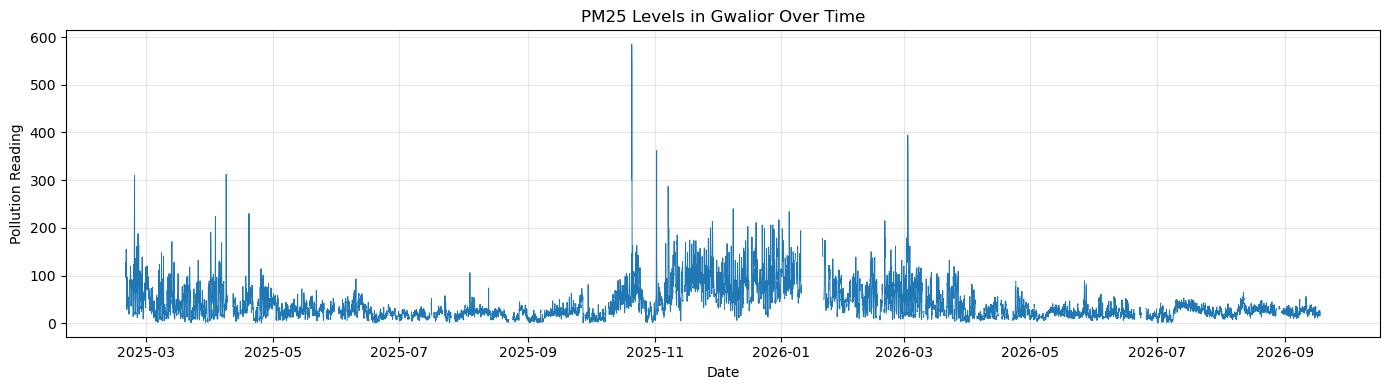

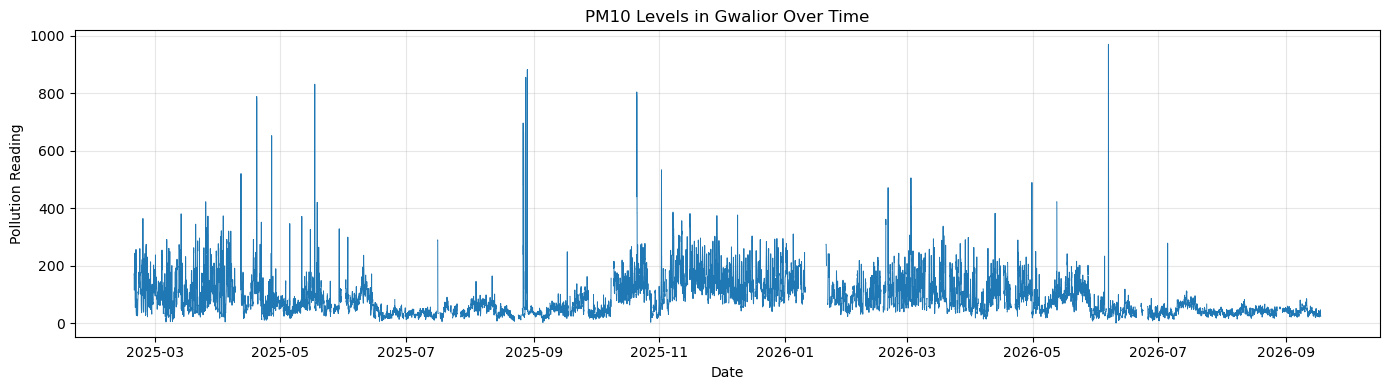

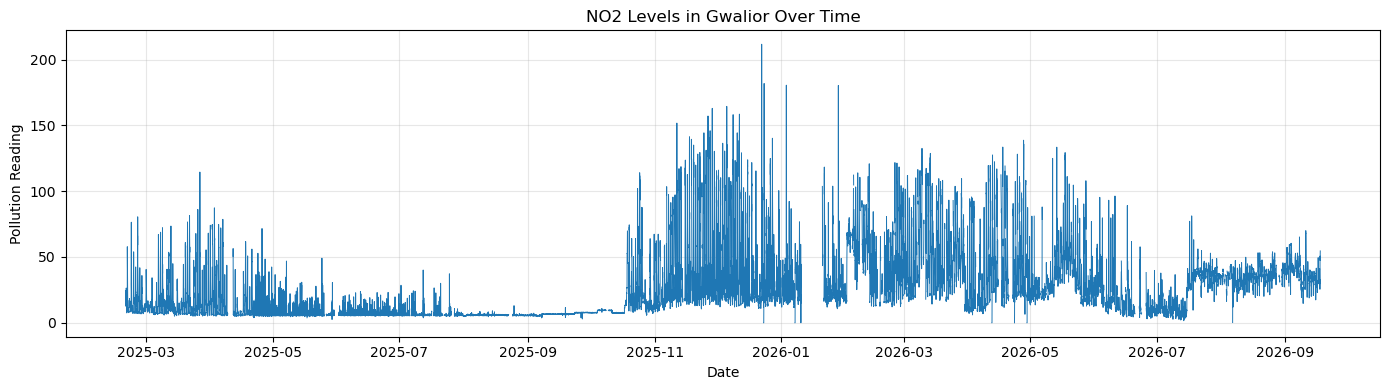

In [44]:
import matplotlib.pyplot as plt

pollutants = ["pm25", "pm10", "no2"]

for pollutant in pollutants:
    plt.figure(figsize=(14, 4))
    plt.plot(
        forecast_data["timestamp"],
        forecast_data[pollutant],
        linewidth=0.7
    )
    plt.title(f"{pollutant.upper()} Levels in Gwalior Over Time")
    plt.xlabel("Date")
    plt.ylabel("Pollution Reading")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

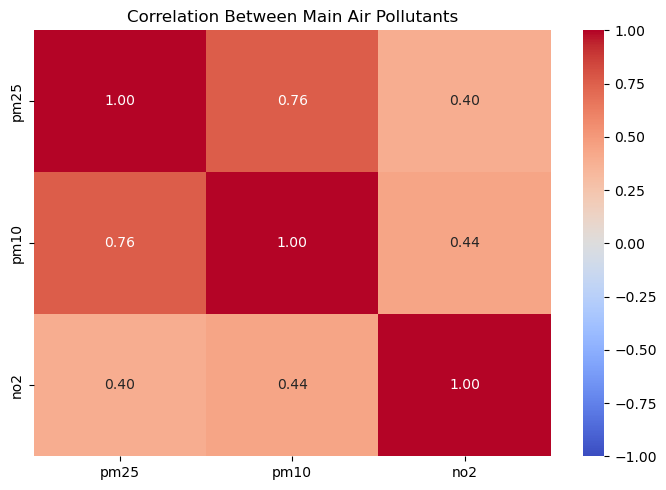

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

pollutants = ["pm25", "pm10", "no2"]

correlation = forecast_data[pollutants].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlation Between Main Air Pollutants")
plt.tight_layout()
plt.show()

In [46]:
print("Rows in model_data:", len(model_data))
print("First timestamp:", model_data["timestamp"].min())
print("Last timestamp:", model_data["timestamp"].max())
print("Chronologically sorted:",
      model_data["timestamp"].is_monotonic_increasing)


Rows in model_data: 37193
First timestamp: 2025-02-20 01:30:00+05:30
Last timestamp: 2026-09-16 19:45:00+05:30
Chronologically sorted: True


In [47]:
# Save the prepared dataset
model_data.to_csv("gwalior_air_quality_model_data.csv", index=False)

print("Dataset saved successfully!")
print("Rows:", len(model_data))
print("File: gwalior_air_quality_model_data.csv")

Dataset saved successfully!
Rows: 37193
File: gwalior_air_quality_model_data.csv


In [2]:
import pandas as pd

model_data = pd.read_csv(
    "gwalior_air_quality_model_data.csv",
    parse_dates=["timestamp"]
)

print("Dataset shape:", model_data.shape)
print("First timestamp:", model_data["timestamp"].min())
print("Last timestamp:", model_data["timestamp"].max())
print("Missing values:", model_data.isnull().sum().sum())

display(model_data.head())

Dataset shape: (37193, 33)
First timestamp: 2025-02-20 01:30:00+05:30
Last timestamp: 2026-09-16 19:45:00+05:30
Missing values: 2537


,timestamp,pm25,pm10,no2,co,so2,o3,temperature,humidity,hour,...,no2_next_24hours,pm25_lag_1,pm25_lag_4,pm25_lag_96,pm10_lag_1,pm10_lag_4,pm10_lag_96,no2_lag_1,no2_lag_4,no2_lag_96
0,2025-02-20 01:30:00+05:30,38.0,39.0,9.3,0.010,16.2,21.1,17.3,90.0,1,...,12.6,48.0,48.0,127.0,65.0,65.0,171.0,9.9,10.7,24.5
1,2025-02-20 01:45:00+05:30,38.0,39.0,8.8,0.210,16.6,21.0,17.0,90.0,1,...,11.9,38.0,48.0,127.0,39.0,65.0,171.0,9.3,10.3,24.0
2,2025-02-20 02:00:00+05:30,38.0,39.0,8.7,0.030,17.0,21.4,16.8,91.0,2,...,12.0,38.0,48.0,127.0,39.0,65.0,171.0,8.8,10.1,23.2
3,2025-02-20 02:15:00+05:30,38.0,39.0,8.8,0.220,16.6,21.8,16.4,91.0,2,...,12.4,38.0,48.0,127.0,39.0,65.0,171.0,8.7,9.9,20.6
4,2025-02-20 02:30:00+05:30,37.0,39.0,8.7,0.285,16.1,21.4,16.4,92.0,2,...,12.9,38.0,38.0,108.0,39.0,39.0,135.0,8.8,9.3,18.0


In [3]:
missing = model_data.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

pm25_previous    2537
dtype: int64


In [4]:
model_data = model_data.drop(columns=["pm25_previous"])

print("Dataset shape:", model_data.shape)
print("Total missing values:", model_data.isnull().sum().sum())

Dataset shape: (37193, 32)
Total missing values: 0


In [7]:
# Input features
features = [
    "pm25", "pm10", "no2",
    "co", "so2", "o3",
    "temperature", "humidity",
    "hour", "day", "month",
    "day_of_week", "is_weekend",
    "pm25_lag_1", "pm25_lag_4", "pm25_lag_96",
    "pm10_lag_1", "pm10_lag_4", "pm10_lag_96",
    "no2_lag_1", "no2_lag_4", "no2_lag_96"
]

# Nine prediction targets
targets = [
    "pm25_next_15min", "pm25_next_1hour", "pm25_next_24hours",
    "pm10_next_15min", "pm10_next_1hour", "pm10_next_24hours",
    "no2_next_15min", "no2_next_1hour", "no2_next_24hours"]

# Separate inputs and future prediction targets
X = model_data[features]
y = model_data[targets]

# Split chronologically: first 80% for training
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training input shape: (29754, 22)
Testing input shape: (7439, 22)
Training target shape: (29754, 9)
Testing target shape: (7439, 9)


In [8]:
from sklearn.linear_model import LinearRegression

# Create the model
lr_model = LinearRegression()

# Train it using the training data
lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [9]:
# Predict future pollution levels
y_pred = lr_model.predict(X_test)

print("Predictions completed successfully!")
print("Prediction array shape:", y_pred.shape)

# Display the first 5 predictions
print("\nFirst 5 predicted values:")
print(y_pred[:5])

Predictions completed successfully!
Prediction array shape: (7439, 9)

First 5 predicted values:
[[ 14.58566746  13.80602996  10.35562472 116.03556233 114.44042816
  100.75086955  29.1718028   29.62683389  25.57356659]
 [ 14.61706542  13.78089876  10.15305185 117.20548309 114.83525312
  100.90353019  30.02081075  30.41364345  26.23616566]
 [ 14.59315224  13.61344092  11.03513302 117.12013438 114.32368892
  102.681443    29.96606844  30.47463142  26.9045451 ]
 [ 14.62586829  13.77664937  10.95475172 117.21602744 114.75076941
  102.58172237  30.31799306  30.89148977  27.08286218]
 [  9.80222043   8.93721083  10.63075871 100.90173453 100.04796043
   97.71060635  29.866837    30.41740293  27.41514806]]


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics for all 9 targets
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Performance")
print("-----------------------------------")
print(f"MAE:  {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R²:   {r2:.3f}")

Linear Regression Model Performance
-----------------------------------
MAE:  6.984
RMSE: 13.123
R²:   0.524


In [11]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

results = []

for i, target in enumerate(targets):
    actual = y_test[target]
    predicted = y_pred[:, i]

    results.append({
        "Target": target,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

results_df = pd.DataFrame(results).round(3)

print(results_df.to_string(index=False))

           Target    MAE   RMSE     R2
  pm25_next_15min  1.562  2.929  0.920
  pm25_next_1hour  4.500  6.347  0.627
pm25_next_24hours  7.641 10.091  0.057
  pm10_next_15min  3.906  6.660  0.914
  pm10_next_1hour 12.004 22.219  0.348
pm10_next_24hours 22.194 26.854 -0.446
   no2_next_15min  1.164  2.285  0.974
   no2_next_1hour  3.462  6.021  0.823
 no2_next_24hours  6.425  9.934  0.501


In [12]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [13]:
# Predict all 9 future pollution targets
rf_pred = rf_model.predict(X_test)

print("Random Forest predictions completed!")
print("Prediction array shape:", rf_pred.shape)

print("\nFirst 5 predictions:")
print(rf_pred[:5])

Random Forest predictions completed!
Prediction array shape: (7439, 9)

First 5 predictions:
[[ 19.18771072  19.3142978   16.18493125 131.59754553 143.60924152
  128.21039532  31.67046201  32.31808041  28.89653595]
 [ 19.33125873  19.40661863  16.1665165  131.74314053 143.68450667
  127.54573559  32.51172545  33.35535961  29.4651797 ]
 [ 19.40990541  19.94145004  15.87982174 131.54274103 150.93480596
  125.50946221  32.42362353  33.41057558  29.30510514]
 [ 19.52348874  19.94928337  15.92682174 131.73082436 150.7206393
  125.38229554  32.65299437  33.58313392  29.48455514]
 [ 20.30401521  20.36951916  21.24324608  99.1089466  100.08803779
  105.50771717  26.98378373  29.9496327   27.93254768]]


In [14]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

rf_results = []

for i, target in enumerate(targets):
    actual = y_test[target]
    predicted = rf_pred[:, i]

    rf_results.append({
        "Target": target,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

rf_results_df = pd.DataFrame(rf_results).round(3)

print("Random Forest Model Performance")
print(rf_results_df.to_string(index=False))

Random Forest Model Performance
           Target    MAE   RMSE     R2
  pm25_next_15min  4.660  6.292  0.633
  pm25_next_1hour  5.538  7.238  0.514
pm25_next_24hours  7.718 10.508 -0.023
  pm10_next_15min  4.792  8.176  0.870
  pm10_next_1hour 10.353 21.844  0.370
pm10_next_24hours 24.224 32.669 -1.141
   no2_next_15min 13.188 18.491 -0.676
   no2_next_1hour 14.089 19.071 -0.776
 no2_next_24hours 14.163 18.497 -0.731


In [15]:
comparison = results_df.merge(
    rf_results_df,
    on="Target",
    suffixes=("_Linear", "_RandomForest")
)

print(comparison.round(3).to_string(index=False))

           Target  MAE_Linear  RMSE_Linear  R2_Linear  MAE_RandomForest  RMSE_RandomForest  R2_RandomForest
  pm25_next_15min       1.562        2.929      0.920             4.660              6.292            0.633
  pm25_next_1hour       4.500        6.347      0.627             5.538              7.238            0.514
pm25_next_24hours       7.641       10.091      0.057             7.718             10.508           -0.023
  pm10_next_15min       3.906        6.660      0.914             4.792              8.176            0.870
  pm10_next_1hour      12.004       22.219      0.348            10.353             21.844            0.370
pm10_next_24hours      22.194       26.854     -0.446            24.224             32.669           -1.141
   no2_next_15min       1.164        2.285      0.974            13.188             18.491           -0.676
   no2_next_1hour       3.462        6.021      0.823            14.089             19.071           -0.776
 no2_next_24hours       6.42

In [16]:
# Examine actual NO2 values in the training and testing sets
no2_columns = [
    "no2",
    "no2_next_15min",
    "no2_next_1hour",
    "no2_next_24hours"
]

print("Training NO2 statistics:")
print(y_train[[
    "no2_next_15min",
    "no2_next_1hour",
    "no2_next_24hours"
]].describe().round(2))

print("\nTesting NO2 statistics:")
print(y_test[[
    "no2_next_15min",
    "no2_next_1hour",
    "no2_next_24hours"
]].describe().round(2))

Training NO2 statistics:
       no2_next_15min  no2_next_1hour  no2_next_24hours
count        29754.00        29754.00          29754.00
mean            23.25           23.31             23.46
std             25.17           25.13             25.44
min              3.80            3.80              0.00
25%              6.20            6.20              6.20
50%             12.20           12.30             12.20
75%             29.50           29.80             29.90
max            211.60          181.80            211.60

Testing NO2 statistics:
       no2_next_15min  no2_next_1hour  no2_next_24hours
count         7439.00         7439.00           7439.00
mean            29.15           29.22             29.42
std             14.29           14.31             14.06
min              2.60            1.60              0.20
25%             16.60           16.70             17.06
50%             32.10           32.20             32.60
75%             38.10           38.20             38.3

In [17]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

gb_model = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
)

gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [18]:
# Generate predictions for the test dataset
gb_pred = gb_model.predict(X_test)

print("Gradient Boosting predictions completed!")
print("Prediction array shape:", gb_pred.shape)

Gradient Boosting predictions completed!
Prediction array shape: (7439, 9)


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

gb_results = []

for i, target in enumerate(targets):
    actual = y_test[target]
    predicted = gb_pred[:, i]

    gb_results.append({
        "Target": target,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    })

gb_results_df = pd.DataFrame(gb_results).round(3)

print("Gradient Boosting Model Performance")
print(gb_results_df.to_string(index=False))

Gradient Boosting Model Performance
           Target    MAE   RMSE     R2
  pm25_next_15min  1.459  2.807  0.927
  pm25_next_1hour  4.096  5.604  0.709
pm25_next_24hours  7.151  9.553  0.155
  pm10_next_15min  3.796  6.621  0.915
  pm10_next_1hour 10.276 20.891  0.423
pm10_next_24hours 23.665 29.587 -0.756
   no2_next_15min  1.210  2.312  0.974
   no2_next_1hour  3.789  6.263  0.808
 no2_next_24hours  6.333  9.896  0.504


In [20]:
final_comparison = results_df.merge(
    gb_results_df,
    on="Target",
    suffixes=("_Linear", "_GradientBoosting")
)

print(final_comparison.round(3).to_string(index=False))

           Target  MAE_Linear  RMSE_Linear  R2_Linear  MAE_GradientBoosting  RMSE_GradientBoosting  R2_GradientBoosting
  pm25_next_15min       1.562        2.929      0.920                 1.459                  2.807                0.927
  pm25_next_1hour       4.500        6.347      0.627                 4.096                  5.604                0.709
pm25_next_24hours       7.641       10.091      0.057                 7.151                  9.553                0.155
  pm10_next_15min       3.906        6.660      0.914                 3.796                  6.621                0.915
  pm10_next_1hour      12.004       22.219      0.348                10.276                 20.891                0.423
pm10_next_24hours      22.194       26.854     -0.446                23.665                 29.587               -0.756
   no2_next_15min       1.164        2.285      0.974                 1.210                  2.312                0.974
   no2_next_1hour       3.462        6.0

In [21]:
print("Last training timestamp:")
print(model_data.iloc[len(X_train) - 1]["timestamp"])

print("\nFirst testing timestamp:")
print(model_data.iloc[len(X_train)]["timestamp"])

Last training timestamp:
2026-05-24 13:15:00+05:30

First testing timestamp:
2026-05-24 13:30:00+05:30


In [22]:
row = model_data.iloc[0]

print("Prediction timestamp:", row["timestamp"])
print("Current PM2.5:", row["pm25"])
print("PM2.5 after 15 minutes:", row["pm25_next_15min"])
print("PM2.5 after 1 hour:", row["pm25_next_1hour"])
print("PM2.5 after 24 hours:", row["pm25_next_24hours"])

Prediction timestamp: 2025-02-20 01:30:00+05:30
Current PM2.5: 38.0
PM2.5 after 15 minutes: 38.0
PM2.5 after 1 hour: 37.0
PM2.5 after 24 hours: 84.0


In [24]:
model_data.loc[
    model_data["timestamp"].isin([
        pd.Timestamp("2025-02-20 01:30:00+05:30"),
        pd.Timestamp("2025-02-20 01:45:00+05:30"),
        pd.Timestamp("2025-02-20 02:30:00+05:30"),
        pd.Timestamp("2025-02-21 01:30:00+05:30")
    ]),
    ["timestamp", "pm25"]
]

,timestamp,pm25
0,2025-02-20 01:30:00+05:30,38.0
1,2025-02-20 01:45:00+05:30,38.0
4,2025-02-20 02:30:00+05:30,37.0
95,2025-02-21 01:30:00+05:30,84.0


In [25]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select 15-minute and 1-hour targets only
targets = [
    "pm25_next_15min", "pm25_next_1hour",
    "pm10_next_15min", "pm10_next_1hour",
    "no2_next_15min", "no2_next_1hour"
]

# Split chronologically, leaving a 1-hour gap
split_index = int(len(model_data) * 0.8)
split_timestamp = model_data.iloc[split_index]["timestamp"]

train_data = model_data[
    model_data["timestamp"] < split_timestamp - pd.Timedelta(hours=1)
]
test_data = model_data[
    model_data["timestamp"] >= split_timestamp
]

X_train, y_train = train_data[features], train_data[targets]
X_test, y_test = test_data[features], test_data[targets]

# Train Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

# Train Gradient Boosting
gb_model = MultiOutputRegressor(
    GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
)
gb_model.fit(X_train, y_train)
gb_predictions = gb_model.predict(X_test)

# Compare model performance
results = []

for name, predictions in [
    ("Linear Regression", lr_predictions),
    ("Gradient Boosting", gb_predictions)
]:
    for i, target in enumerate(targets):
        actual = y_test[target]
        predicted = predictions[:, i]

        results.append({
            "Model": name,
            "Target": target,
            "MAE": round(mean_absolute_error(actual, predicted), 3),
            "RMSE": round(np.sqrt(mean_squared_error(actual, predicted)), 3),
            "R2": round(r2_score(actual, predicted), 3)
        })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Target,MAE,RMSE,R2
0,Linear Regression,pm25_next_15min,1.562,2.929,0.920
1,Linear Regression,pm25_next_1hour,4.500,6.347,0.627
2,Linear Regression,pm10_next_15min,3.906,6.660,0.914
3,Linear Regression,pm10_next_1hour,12.004,22.219,0.348
4,Linear Regression,no2_next_15min,1.164,2.285,0.974
5,Linear Regression,no2_next_1hour,3.462,6.021,0.823
6,Gradient Boosting,pm25_next_15min,1.456,2.807,0.927
7,Gradient Boosting,pm25_next_1hour,4.065,5.579,0.712
8,Gradient Boosting,pm10_next_15min,3.623,6.454,0.919
9,Gradient Boosting,pm10_next_1hour,10.325,20.875,0.424


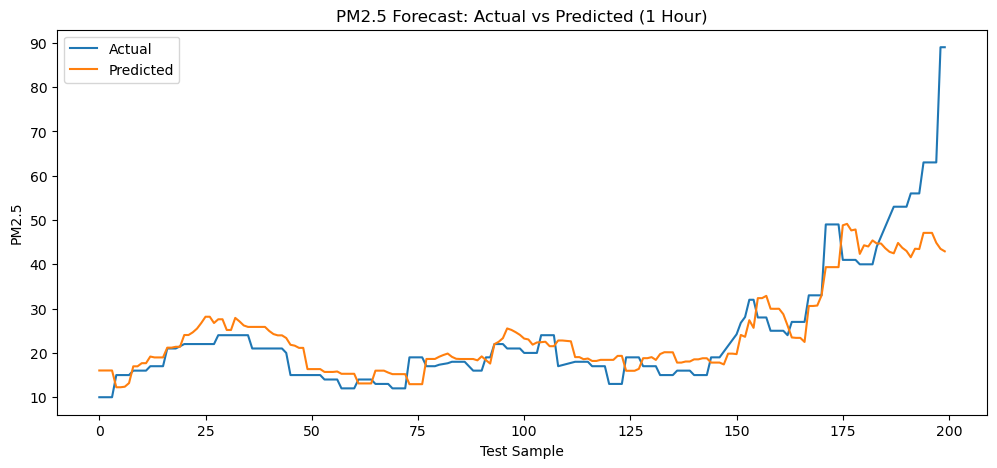

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    y_test["pm25_next_1hour"].iloc[:200].values,
    label="Actual"
)

plt.plot(
    gb_predictions[:200, targets.index("pm25_next_1hour")],
    label="Predicted"
)

plt.title("PM2.5 Forecast: Actual vs Predicted (1 Hour)")
plt.xlabel("Test Sample")
plt.ylabel("PM2.5")
plt.legend()
plt.show()

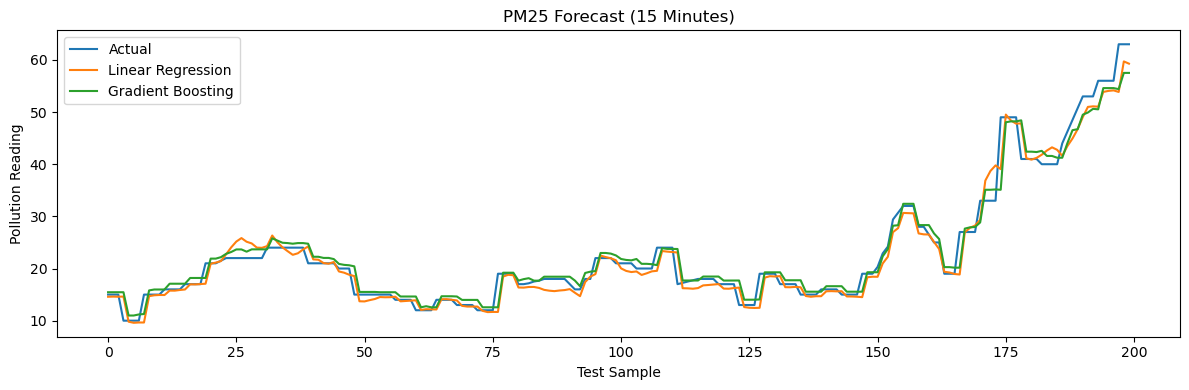

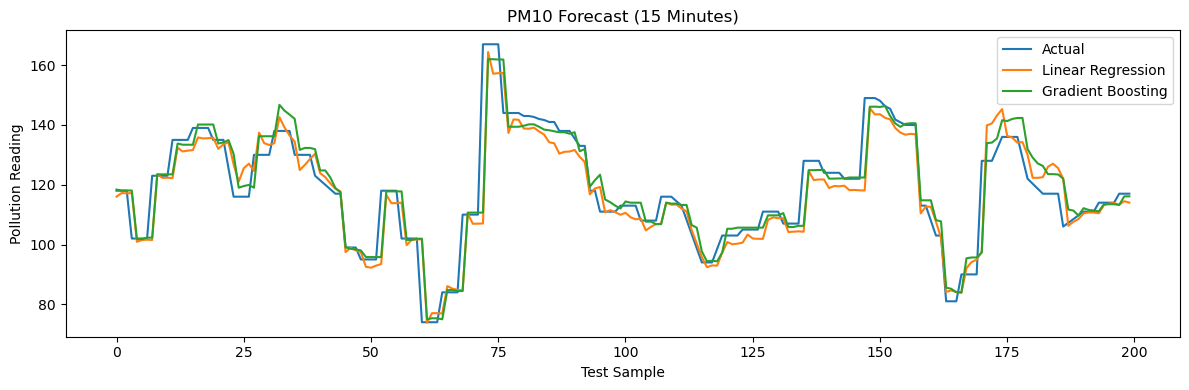

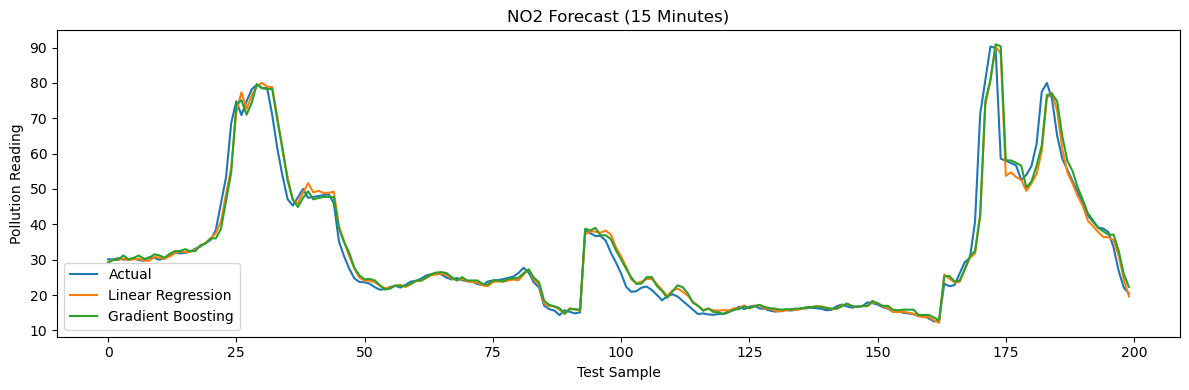

In [27]:
import matplotlib.pyplot as plt

pollutants = ["pm25", "pm10", "no2"]

for pollutant in pollutants:
    target = f"{pollutant}_next_15min"
    i = targets.index(target)

    plt.figure(figsize=(12, 4))

    plt.plot(y_test[target].iloc[:200].values,
             label="Actual")

    plt.plot(lr_predictions[:200, i],
             label="Linear Regression")

    plt.plot(gb_predictions[:200, i],
             label="Gradient Boosting")

    plt.title(f"{pollutant.upper()} Forecast (15 Minutes)")
    plt.xlabel("Test Sample")
    plt.ylabel("Pollution Reading")
    plt.legend()
    plt.tight_layout()
    plt.show()

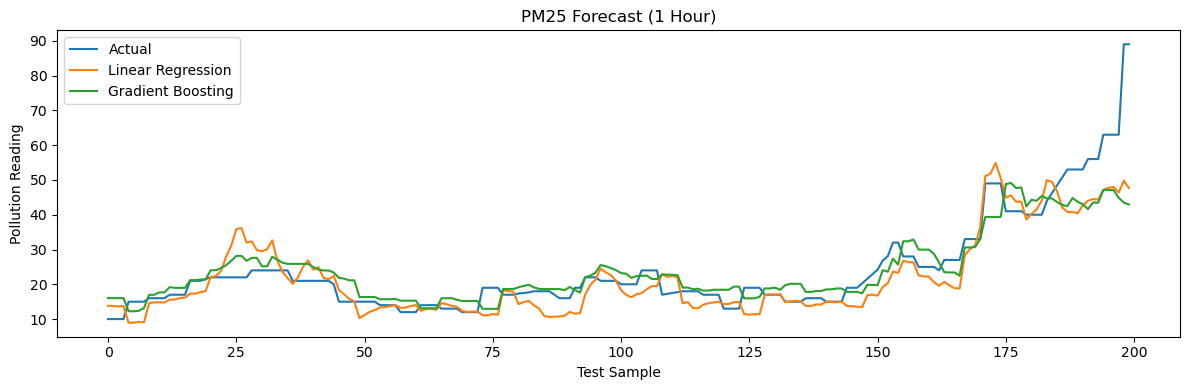

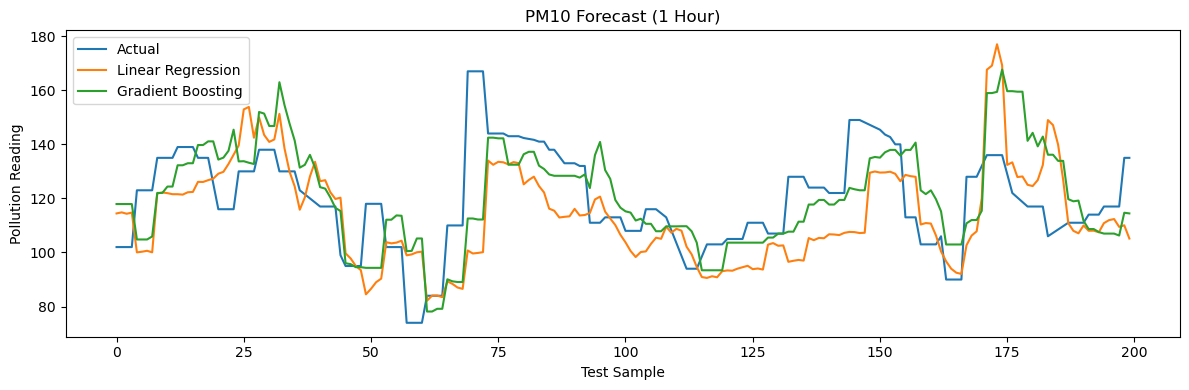

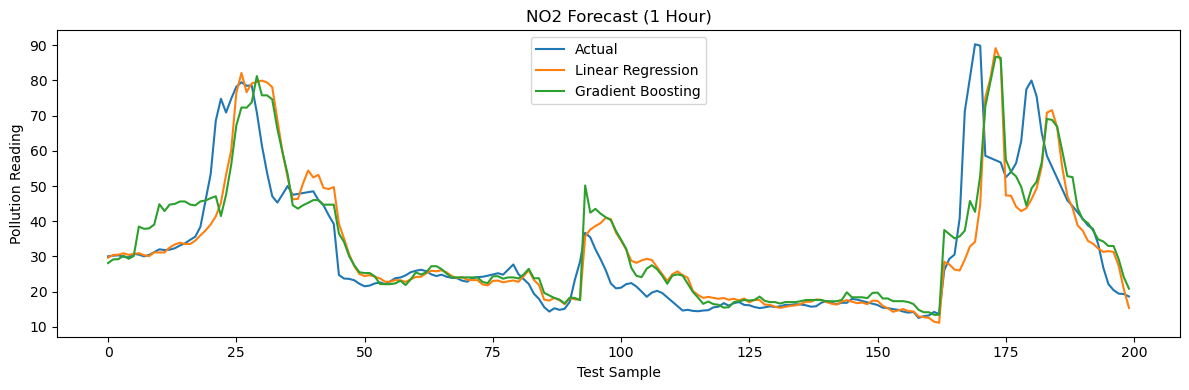

In [28]:
import matplotlib.pyplot as plt

pollutants = ["pm25", "pm10", "no2"]

for pollutant in pollutants:
    target = f"{pollutant}_next_1hour"
    i = targets.index(target)

    plt.figure(figsize=(12, 4))

    plt.plot(y_test[target].iloc[:200].values,
             label="Actual")

    plt.plot(lr_predictions[:200, i],
             label="Linear Regression")

    plt.plot(gb_predictions[:200, i],
             label="Gradient Boosting")

    plt.title(f"{pollutant.upper()} Forecast (1 Hour)")
    plt.xlabel("Test Sample")
    plt.ylabel("Pollution Reading")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [29]:
import joblib

joblib.dump(gb_model, "gradient_boosting_model.pkl")
joblib.dump(lr_model, "linear_regression_model.pkl")

print("Models saved successfully!")

Models saved successfully!


In [30]:
def predict_pollution(input_data):
    prediction = gb_model.predict(input_data[features])

    results = {}

    for i, target in enumerate(targets):
        results[target] = round(prediction[0][i], 2)

    return results


print("Prediction function created successfully!")

Prediction function created successfully!


In [32]:
import requests

url = "https://api.waqi.info/feed/@12817/?token=27016ba2d20e77fdd6bfb88c3c60048e41486755"

response = requests.get(url, timeout=20)
result = response.json()

print("Status:", result.get("status"))

if result.get("status") == "ok":
    print("Updated:", result["data"].get("time"))
    print("Pollutants:", result["data"].get("iaqi"))
else:
    print(result)

Status: ok
Updated: {'s': '2026-06-23 10:00:00', 'tz': '+05:30', 'v': 1782208800, 'iso': '2026-06-23T10:00:00+05:30'}
Pollutants: {'co': {'v': 6}, 'dew': {'v': 21}, 'h': {'v': 46.5}, 'no2': {'v': 3.2}, 'o3': {'v': 35.3}, 'p': {'v': 731}, 'pm10': {'v': 40}, 'pm25': {'v': 71}, 'so2': {'v': 16.4}, 't': {'v': 22.25}, 'w': {'v': 0.6499999999999999}, 'wg': {'v': 8.7}}


In [67]:
import requests

url = "https://api.openaq.org/v3/locations/10907/latest"

headers = {
    "X-API-Key": "fc3225065e4850225ad568f999814ee9408557fe05db6dc429a98164c7df439f"
}

response = requests.get(url, headers=headers, timeout=20)

print("Status:", response.status_code)

if response.status_code == 200:
    readings = response.json()["results"]

    for r in readings:
        print(
            "Sensor:", r.get("sensorsId"),
            "| Value:", r.get("value"),
            "| Time:", r.get("datetime", {}).get("local")
        )
else:
    print(response.text)

Status: 200
Sensor: 12236152 | Value: 137.0 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236154 | Value: 77.0 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236156 | Value: 22.6 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236148 | Value: 3.24 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236151 | Value: 94.6 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236155 | Value: 38.5 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236149 | Value: 45.7 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236153 | Value: 58.0 | Time: 2026-10-28T19:30:00+05:30
Sensor: 12236150 | Value: 138.6 | Time: 2026-10-28T19:30:00+05:30
Sensor: 14340982 | Value: 0.3 | Time: 2026-10-28T19:30:00+05:30
Sensor: 14340981 | Value: 149.0 | Time: 2026-10-28T19:30:00+05:30
Sensor: 14340980 | Value: 0.10890000000000001 | Time: 2026-10-28T19:30:00+05:30
Sensor: 36584 | Value: 59.0 | Time: 2022-10-16T21:30:00+05:30
Sensor: 36593 | Value: 23.8 | Time: 2022-10-16T21:30:00+05:30
Sensor: 36580 | Value: 9.7 | Time: 2022-10-16T21:30:00+05:30
Sensor

In [68]:
import os
import joblib

# Check available model files
print(os.listdir())

['.ipynb_checkpoints', '03_Data_Cleaning_EDA.ipynb', 'gradient_boosting_model.pkl', 'gwalior_air_quality_model_data.csv', 'linear_regression_model.pkl']


In [69]:
gb_model = joblib.load("gradient_boosting_model.pkl")
lr_model = joblib.load("linear_regression_model.pkl")

print("Both models loaded successfully!")

Both models loaded successfully!


In [72]:
import os
import getpass

API_KEY = getpass.getpass("Enter your OpenAQ API key:fc3225065e4850225ad568f999814ee9408557fe05db6dc429a98164c7df439f ")

headers = {"X-API-Key": API_KEY}

print("API key loaded.")

Enter your OpenAQ API key:fc3225065e4850225ad568f999814ee9408557fe05db6dc429a98164c7df439f  ········


API key loaded.


In [73]:
import requests
import pandas as pd

headers = {"X-API-Key": API_KEY}

sensor_ids = {
    12236153: "pm25",
    12236152: "pm10",
    12236150: "no2",
    12236148: "co",
    12236155: "so2",
    12236151: "o3",
    12236156: "temperature",
    12236154: "humidity"
}

latest_readings = []

for sensor_id, pollutant in sensor_ids.items():
    url = f"https://api.openaq.org/v3/locations/10907/latest"

    response = requests.get(
        url,
        headers=headers,
        timeout=30
    )
    response.raise_for_status()

    for item in response.json().get("results", []):
        if item.get("sensorsId") == sensor_id:
            latest_readings.append({
                "pollutant": pollutant,
                "value": item.get("value"),
                "timestamp": item.get("datetime", {}).get("local")
            })

latest_data = pd.DataFrame(latest_readings)

print(latest_data)

     pollutant   value                  timestamp
0         pm25   58.00  2026-10-28T19:30:00+05:30
1         pm10  137.00  2026-10-28T19:30:00+05:30
2          no2  138.60  2026-10-28T19:30:00+05:30
3           co    3.24  2026-10-28T19:30:00+05:30
4          so2   38.50  2026-10-28T19:30:00+05:30
5           o3   94.60  2026-10-28T19:30:00+05:30
6  temperature   22.60  2026-10-28T19:30:00+05:30
7     humidity   77.00  2026-10-28T19:30:00+05:30


In [74]:
print("Number of features:", len(features))
print("\nFeatures required by the model:")

for i, feature in enumerate(features, start=1):
    print(i, feature)

Number of features: 22

Features required by the model:
1 pm25
2 pm10
3 no2
4 co
5 so2
6 o3
7 temperature
8 humidity
9 hour
10 day
11 month
12 day_of_week
13 is_weekend
14 pm25_lag_1
15 pm25_lag_4
16 pm25_lag_96
17 pm10_lag_1
18 pm10_lag_4
19 pm10_lag_96
20 no2_lag_1
21 no2_lag_4
22 no2_lag_96


In [75]:
print("Available historical-data variables:")

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        if any(col in obj.columns for col in ["timestamp", "pm25", "pm10"]):
            print(name, obj.shape, list(obj.columns)[:10])

Available historical-data variables:
_ (4, 2) ['timestamp', 'pm25']
model_data (37193, 35) ['timestamp', 'pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour']
X (37193, 22) ['pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day']
X_train (29750, 22) ['pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day']
X_test (7439, 22) ['pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day']
_24 (4, 2) ['timestamp', 'pm25']
train_data (29750, 32) ['timestamp', 'pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour']
test_data (7439, 32) ['timestamp', 'pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour']
temp (37193, 34) ['pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour', 'day']
model_data_6h (30540, 35) ['timestamp', 'pm25', 'pm10', 'no2', 'co', 'so2', 'o3', 'temperature', 'humidity', 'hour']
X_6h (30540, 22) ['pm25', 'pm10',

In [76]:
url = "https://api.openaq.org/v3/sensors/12236153/measurements"

response = requests.get(
    url,
    headers=headers,
    params={
        "datetime_from": "2026-10-28T00:00:00+05:30",
        "datetime_to": "2026-10-29T00:00:00+05:30",
        "limit": 1000,
        "page": 1
    },
    timeout=30
)

print("Status:", response.status_code)

if response.status_code == 200:
    recent_pm25 = pd.DataFrame([
        {
            "timestamp": item["period"]["datetimeFrom"]["local"],
            "pm25": item["value"]
        }
        for item in response.json().get("results", [])
    ])

    print("Recent readings:", len(recent_pm25))
    print(recent_pm25.tail(10).to_string(index=False))
else:
    print(response.text[:1000])

Status: 200
Recent readings: 76
                timestamp  pm25
2026-10-28T17:00:00+05:30  43.0
2026-10-28T17:15:00+05:30  43.0
2026-10-28T17:30:00+05:30  49.0
2026-10-28T17:45:00+05:30  49.0
2026-10-28T18:00:00+05:30  49.0
2026-10-28T18:15:00+05:30  49.0
2026-10-28T18:30:00+05:30  58.0
2026-10-28T18:45:00+05:30  58.0
2026-10-28T19:00:00+05:30  58.0
2026-10-28T19:15:00+05:30  58.0


In [77]:
import requests
import pandas as pd

sensor_ids = {
    12236153: "pm25",
    12236152: "pm10",
    12236150: "no2",
    12236148: "co",
    12236155: "so2",
    12236151: "o3",
    12236156: "temperature",
    12236154: "humidity"
}

recent_readings = []

for sensor_id, pollutant in sensor_ids.items():
    url = f"https://api.openaq.org/v3/sensors/{sensor_id}/measurements"

    response = requests.get(
        url,
        headers=headers,
        params={
            "datetime_from": "2026-10-27T00:00:00+05:30",
            "datetime_to": "2026-10-29T00:00:00+05:30",
            "limit": 1000,
            "page": 1
        },
        timeout=30
    )

    if response.status_code == 200:
        for item in response.json().get("results", []):
            recent_readings.append({
                "timestamp": item["period"]["datetimeFrom"]["local"],
                "pollutant": pollutant,
                "value": item["value"]
            })
    else:
        print(f"{pollutant}: API error {response.status_code}")

recent_data = pd.DataFrame(recent_readings)

if not recent_data.empty:
    recent_data["timestamp"] = pd.to_datetime(recent_data["timestamp"])
    recent_wide = recent_data.pivot_table(
        index="timestamp",
        columns="pollutant",
        values="value",
        aggfunc="last"
    ).sort_index()

    print("Recent data shape:", recent_wide.shape)
    print("\nReadings available per pollutant:")
    print(recent_wide.notna().sum().sort_values(ascending=False))
    print("\nLatest 5 timestamps:")
    print(recent_wide.tail().to_string())
else:
    print("No recent readings were returned.")

Recent data shape: (136, 8)

Readings available per pollutant:
pollutant
humidity       136
pm25           136
temperature    136
so2            130
no2            129
o3             126
co             124
pm10           123
dtype: int64

Latest 5 timestamps:
pollutant                    co  humidity    no2     o3   pm10  pm25   so2  temperature
timestamp                                                                              
2026-10-28 18:15:00+05:30  2.08      73.0  131.7  144.8  116.0  49.0  38.3         23.2
2026-10-28 18:30:00+05:30  2.58      74.0  133.9    NaN  137.0  58.0  40.4         23.1
2026-10-28 18:45:00+05:30  3.00      75.0  126.6  219.1  137.0  58.0  39.2         23.0
2026-10-28 19:00:00+05:30  2.92      76.0  133.1   69.2  137.0  58.0  38.5         22.7
2026-10-28 19:15:00+05:30  3.24      77.0  138.6   94.6  137.0  58.0  38.5         22.6


In [78]:
# Put readings on a regular 15-minute timeline
recent_wide = recent_wide.sort_index()

full_index = pd.date_range(
    start=recent_wide.index.min(),
    end=recent_wide.index.max(),
    freq="15min"
)

recent_wide = recent_wide.reindex(full_index)
recent_wide.index.name = "timestamp"

# Fill only short gaps using time-based interpolation
recent_wide = recent_wide.interpolate(
    method="time",
    limit=4,
    limit_area="inside"
)

print("Timeline rows:", len(recent_wide))
print("\nMissing values after cleaning:")
print(recent_wide.isna().sum())
print("\nLatest readings:")
print(recent_wide.tail(3).to_string())

Timeline rows: 140

Missing values after cleaning:
pollutant
co             0
humidity       0
no2            0
o3             3
pm10           0
pm25           0
so2            0
temperature    0
dtype: int64

Latest readings:
pollutant                    co  humidity    no2     o3   pm10  pm25   so2  temperature
timestamp                                                                              
2026-10-28 18:45:00+05:30  3.00      75.0  126.6  219.1  137.0  58.0  39.2         23.0
2026-10-28 19:00:00+05:30  2.92      76.0  133.1   69.2  137.0  58.0  38.5         22.7
2026-10-28 19:15:00+05:30  3.24      77.0  138.6   94.6  137.0  58.0  38.5         22.6


In [79]:
# Fill the remaining short ozone gaps
recent_wide = recent_wide.interpolate(
    method="time",
    limit_direction="both"
)

# Create model input from the latest timestamp
forecast_input = recent_wide.copy()

# Calendar features
forecast_input["hour"] = forecast_input.index.hour
forecast_input["day"] = forecast_input.index.day
forecast_input["month"] = forecast_input.index.month
forecast_input["day_of_week"] = forecast_input.index.dayofweek
forecast_input["is_weekend"] = (
    forecast_input.index.dayofweek >= 5
).astype(int)

# Lag features for PM2.5, PM10, and NO2
for pollutant in ["pm25", "pm10", "no2"]:
    for lag in [1, 4, 96]:
        forecast_input[f"{pollutant}_lag_{lag}"] = (
            forecast_input[pollutant].shift(lag)
        )

# Select the latest row and arrange features exactly as trained
latest_input = forecast_input[features].iloc[[-1]]

print("Forecast input timestamp:", latest_input.index[0])
print("Input shape:", latest_input.shape)
print("Missing feature values:", latest_input.isna().sum().sum())
print(latest_input.to_string())

Forecast input timestamp: 2026-10-28 19:15:00+05:30
Input shape: (1, 22)
Missing feature values: 0
pollutant                  pm25   pm10    no2    co   so2    o3  temperature  humidity  hour  day  month  day_of_week  is_weekend  pm25_lag_1  pm25_lag_4  pm25_lag_96  pm10_lag_1  pm10_lag_4  pm10_lag_96  no2_lag_1  no2_lag_4  no2_lag_96
timestamp                                                                                                                                                                                                                                    
2026-10-28 19:15:00+05:30  58.0  137.0  138.6  3.24  38.5  94.6         22.6      77.0    19   28     10            2           0        58.0        49.0         83.0       137.0       116.0        166.0      133.1      131.7       143.1


In [86]:
gb_predictions = gb_model.predict(latest_input[features])[0]
lr_predictions = lr_model.predict(latest_input[features])[0]

forecast_table = pd.DataFrame({
    "Target": targets,
    "Gradient_Boosting": gb_predictions,
    "Linear_Regression": lr_predictions
})

forecast_table["Model_Average"] = (
    forecast_table["Gradient_Boosting"] +
    forecast_table["Linear_Regression"]
) / 2

print(forecast_table.round(2).to_string(index=False))

         Target  Gradient_Boosting  Linear_Regression  Model_Average
pm25_next_15min              60.63              62.58          61.60
pm25_next_1hour              72.69              74.31          73.50
pm10_next_15min             148.26             147.00         147.63
pm10_next_1hour             179.80             171.15         175.48
 no2_next_15min             131.52             138.15         134.83
 no2_next_1hour             112.64             133.19         122.91


In [87]:
print("Latest readings:", latest_data.shape)
print("Recent history:", recent_wide.shape)
print("Forecast input:", latest_input.shape)

print("\nLatest API measurement:")
print(latest_data["timestamp"].max())

print("\nMissing values in recent history:")
print(recent_wide.isna().sum())

Latest readings: (8, 3)
Recent history: (140, 8)
Forecast input: (1, 22)

Latest API measurement:
2026-10-28T19:30:00+05:30

Missing values in recent history:
pollutant
co             0
humidity       0
no2            0
o3             0
pm10           0
pm25           0
so2            0
temperature    0
dtype: int64


In [88]:
from pathlib import Path

OUTPUT_DIR = Path("gwalior_air_quality_output")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save the latest available readings
latest_data.to_csv(
    OUTPUT_DIR / "gwalior_latest_readings.csv",
    index=False
)

# Save the current forecasts
forecast_table.to_csv(
    OUTPUT_DIR / "gwalior_pollution_forecast.csv",
    index=False
)

print("Files saved in:", OUTPUT_DIR.resolve())
print("Latest readings and forecasts saved successfully.")

Files saved in: C:\Users\LOQ\Gwalior AQI Project\03_data_cleaning\gwalior_air_quality_output
Latest readings and forecasts saved successfully.


In [89]:
import requests
import pandas as pd

url = "https://api.openaq.org/v3/locations/10907/latest"

response = requests.get(
    url,
    headers=headers,
    timeout=30
)

print("API status:", response.status_code)

if response.status_code == 200:
    print("OpenAQ connection successful!")
    print("Readings returned:", len(response.json().get("results", [])))
else:
    print(response.text[:500])

API status: 200
OpenAQ connection successful!
Readings returned: 18


In [90]:
import pandas as pd

results = response.json()["results"]

sensor_map = {
    12236153: "pm25",
    12236152: "pm10",
    12236150: "no2",
    12236148: "co",
    12236155: "so2",
    12236151: "o3",
    12236156: "temperature",
    12236154: "humidity"
}

rows = []

for item in results:
    sensor_id = item.get("sensorsId")

    if sensor_id in sensor_map:
        rows.append({
            "pollutant": sensor_map[sensor_id],
            "value": item.get("value"),
            "timestamp": item.get("datetime", {}).get("utc")
        })

fresh_data = pd.DataFrame(rows)

print(fresh_data.to_string(index=False))
print("\nReadings found:", len(fresh_data))

  pollutant  value            timestamp
       pm10 155.00 2026-10-28T15:00:00Z
   humidity  80.00 2026-10-28T15:00:00Z
temperature  21.90 2026-10-28T15:00:00Z
         co   2.93 2026-10-28T15:00:00Z
         o3  38.20 2026-10-28T15:00:00Z
        so2  29.10 2026-10-28T15:00:00Z
       pm25  83.00 2026-10-28T15:00:00Z
        no2 137.30 2026-10-28T15:00:00Z

Readings found: 8


In [91]:
fresh_data["timestamp"] = pd.to_datetime(
    fresh_data["timestamp"], utc=True
).dt.tz_convert("Asia/Kolkata")

latest_row = fresh_data.pivot_table(
    index="timestamp",
    columns="pollutant",
    values="value",
    aggfunc="last"
).reset_index()

print(latest_row.to_string(index=False))

                timestamp   co  humidity   no2   o3  pm10  pm25  so2  temperature
2026-10-28 20:30:00+05:30 2.93      80.0 137.3 38.2 155.0  83.0 29.1         21.9


In [92]:
# Convert the new row to the same column order as recent_wide
latest_row = latest_row.set_index("timestamp")
latest_row = latest_row.reindex(columns=recent_wide.columns)

# Merge with recent history and keep the latest row for duplicate timestamps
updated_history = pd.concat([recent_wide, latest_row])
updated_history = updated_history[
    ~updated_history.index.duplicated(keep="last")
].sort_index()

print("Updated history shape:", updated_history.shape)
print("Latest timestamp:", updated_history.index.max())
print("\nMissing values:")
print(updated_history.isna().sum())

Updated history shape: (141, 8)
Latest timestamp: 2026-10-28 20:30:00+05:30

Missing values:
pollutant
co             0
humidity       0
no2            0
o3             0
pm10           0
pm25           0
so2            0
temperature    0
dtype: int64


In [93]:
# Ensure chronological order
updated_history = updated_history.sort_index()

# Create model features
forecast_input = updated_history.copy()

forecast_input["hour"] = forecast_input.index.hour
forecast_input["day"] = forecast_input.index.day
forecast_input["month"] = forecast_input.index.month
forecast_input["day_of_week"] = forecast_input.index.dayofweek
forecast_input["is_weekend"] = (
    forecast_input["day_of_week"] >= 5
).astype(int)

# Lag features for PM2.5, PM10 and NO2
for pollutant in ["pm25", "pm10", "no2"]:
    for lag in [1, 4, 96]:
        forecast_input[f"{pollutant}_lag_{lag}"] = (
            forecast_input[pollutant].shift(lag)
        )

# Select the latest row and required model features
latest_input = forecast_input[features].iloc[[-1]]

print("Latest timestamp:", forecast_input.index[-1])
print("Model input shape:", latest_input.shape)
print("Missing feature values:", latest_input.isna().sum().sum())

AttributeError: 'Index' object has no attribute 'hour'

In [94]:
updated_history.index = pd.to_datetime(updated_history.index)
updated_history = updated_history.sort_index()

print(type(updated_history.index))
print(updated_history.index[-1])

ValueError: Tz-aware datetime.datetime cannot be converted to datetime64 unless utc=True, at position 140

In [95]:
updated_history.index = pd.to_datetime(updated_history.index, utc=True)
updated_history = updated_history.sort_index()

print(type(updated_history.index))
print("Latest timestamp:", updated_history.index[-1])

<class 'pandas.core.indexes.datetimes.DatetimeIndex'>
Latest timestamp: 2026-10-28 15:00:00+00:00


In [96]:
# Remove duplicate timestamps and sort
updated_history = updated_history[
    ~updated_history.index.duplicated(keep="last")
].sort_index()

# Create regular 15-minute intervals
updated_history = updated_history.resample("15min").mean()

# Fill only short gaps between readings
updated_history = updated_history.interpolate(
    method="time",
    limit=3,
    limit_area="inside"
)

print("Shape:", updated_history.shape)
print("Latest timestamp:", updated_history.index[-1])
print("\nMissing values:")
print(updated_history.isnull().sum())

Shape: (145, 8)
Latest timestamp: 2026-10-28 15:00:00+00:00

Missing values:
pollutant
co             1
humidity       1
no2            1
o3             1
pm10           1
pm25           1
so2            1
temperature    1
dtype: int64


In [97]:
from pathlib import Path

print("CURRENT FOLDER:", Path.cwd())

print("\nMODEL FILES:")
for p in Path.cwd().rglob("*.pkl"):
    print(p)
for p in Path.cwd().rglob("*.joblib"):
    print(p)

print("\nRECENT DATA/OUTPUT FILES:")
for p in Path.cwd().rglob("*.csv"):
    if "gwalior_air_quality_output" in str(p) or p.name in [
        "gwalior_air_quality_historical.csv",
        "latest_forecast.csv",
        "updated_air_quality_history.csv"
    ]:
        print(p)

CURRENT FOLDER: C:\Users\LOQ\Gwalior AQI Project\03_data_cleaning

MODEL FILES:
C:\Users\LOQ\Gwalior AQI Project\03_data_cleaning\gradient_boosting_model.pkl
C:\Users\LOQ\Gwalior AQI Project\03_data_cleaning\linear_regression_model.pkl

RECENT DATA/OUTPUT FILES:
C:\Users\LOQ\Gwalior AQI Project\03_data_cleaning\gwalior_air_quality_output\gwalior_latest_readings.csv
C:\Users\LOQ\Gwalior AQI Project\03_data_cleaning\gwalior_air_quality_output\gwalior_pollution_forecast.csv
